### Chapter 16 — Example 16.3
## Comparison: Q-Learning vs GA vs Random Search

Compares three optimization methods for trajectory synthesis with a fixed budget of 300 evaluations.

**Book:** *Four-Bar Mechanism Synthesis with AI*

## 1. Common objective function

In [15]:
from numpy import *
import random as rnd

random.seed(0); rnd.seed(0)

def fk(a, b, c, d, n=40):
    th2 = linspace(0, 2*pi, n)
    return a*cos(th2)+b*cos(th2*0.9+0.3), a*sin(th2)+b*sin(th2*0.9+0.3)

X_obj, Y_obj = fk(1.0, 2.5, 2.0, 2.8)
D_MIN, D_MAX = 0.5, 4.0; BUDGET = 300

def error(a, b, c, d):
    X,Y = fk(a,b,c,d)
    return mean(sqrt((X-X_obj)**2+(Y-Y_obj)**2))
print('Environment ready')

Environment ready


## 2. Random search

In [16]:
def random_search(budget):
    best_e=inf; hist=[]
    for _ in range(budget):
        p=random.uniform(D_MIN,D_MAX,4)
        e=error(*p)
        if e<best_e: best_e=e
        hist.append(best_e)
    return hist
hist_rnd = random_search(BUDGET)
print(f'Random — final error: {hist_rnd[-1]:.4f}')

Random — final error: 0.0136


## 3. Genetic algorithm

In [17]:
def ag_search(budget, pop=20):
    pop_arr = random.uniform(D_MIN, D_MAX, (pop, 4))
    # Save errors to avoid re-evaluating the same solutions
    errors = array([error(*p) for p in pop_arr])
    evals_used = pop
    best_e = min(errors)
    hist = [best_e] * evals_used

    while evals_used < budget:
        idx = argsort(errors)[:pop//2]
        elite = pop_arr[idx]
        children = []

        while len(children) < pop // 2:
            # Safely use the random integer generator
            p1 = elite[rnd.randint(0, len(elite) - 1)]
            p2 = elite[rnd.randint(0, len(elite) - 1)]
            child = where(random.rand(4) < 0.5, p1, p2) + 0.05 * random.randn(4)
            children.append(clip(child, D_MIN, D_MAX))

        children = array(children)
        # Evaluate only the new solutions (children)
        child_errors = array([error(*p) for p in children])
        evals_used += len(children)

        pop_arr = vstack([elite, children])
        errors = concatenate([errors[idx], child_errors])

        best_e = min(errors)
        # Fill history with the best current error for each consumed evaluation
        hist.extend([best_e] * len(children))

    return hist[:budget]

hist_ag = ag_search(BUDGET)
print(f'GA — final error: {hist_ag[-1]:.4f}')

GA — final error: 0.0018


## 4. Q-learning

In [18]:
def ql_search(budget):
    NS, NA = 6, 4
    DELTA = (D_MAX - D_MIN) / (NS - 1)
    Q = zeros((NS, NS, NS, NS, NA))
    ACTS = [(DELTA, 0, 0, 0), (-DELTA, 0, 0, 0), (0, DELTA, 0, 0), (0, -DELTA, 0, 0)]

    disc = lambda v: int(clip((v - D_MIN) / (D_MAX - D_MIN) * (NS - 1), 0, NS - 1))
    sidx = lambda p: tuple(disc(x) for x in p)

    eps = 1.0
    alpha = 0.1
    gamma = 0.9
    best_e = inf
    hist = []

    p = random.uniform(D_MIN, D_MAX, 4)
    # First evaluation to initialize
    e_curr = error(*p)
    if e_curr < best_e:
        best_e = e_curr
    hist.append(best_e)

    # The loop consumes budget - 1 evaluations
    for _ in range(1, budget):
        s = sidx(p)
        if rnd.random() < eps:
            act = rnd.randint(0, NA - 1)
        else:
            # Explicitly use NumPy's amax to avoid conflicts with native max
            act = int(argmax(Q[s]))

        p2 = clip(p + array(ACTS[act]), D_MIN, D_MAX)
        e2 = error(*p2)
        r = -e2

        s2 = sidx(p2)
        # Q-learning update using explicit NumPy amax
        Q[s][act] += alpha * (r + gamma * amax(Q[s2]) - Q[s][act])

        p = p2
        # Calculate eps decay without using numpy max function
        decay_eps = eps * 0.995
        eps = decay_eps if decay_eps > 0.05 else 0.05

        if e2 < best_e:
            best_e = e2
        hist.append(best_e)

    return hist

hist_ql = ql_search(BUDGET)
print(f'Q-learning — final error: {hist_ql[-1]:.4f}')

Q-learning — final error: 0.1542


## 5. Visual comparison

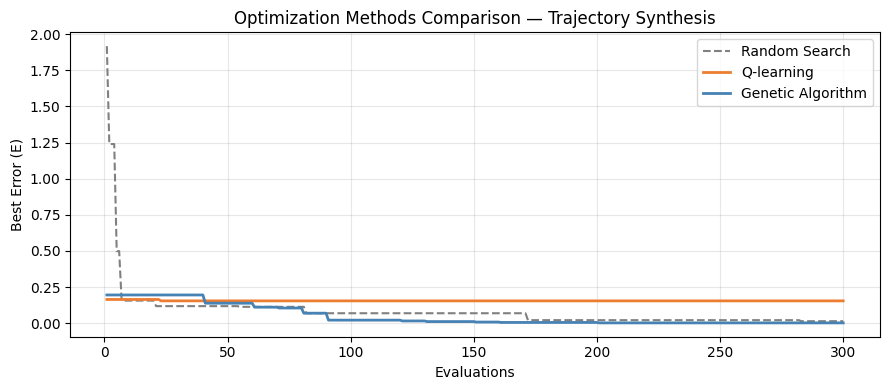

               PERFORMANCE COMPARISON SUMMARY               
 Method                    | Final Error  | vs. Random Search 
------------------------------------------------------------
 Random Search             | 0.0136       | Baseline        
 Q-learning                | 0.1542       | +1036.6% error 
 Genetic Algorithm         | 0.0018       | -86.6% error 


In [21]:
import matplotlib.pyplot as plt

iters = arange(1, BUDGET+1)
plt.figure(figsize=(9, 4))
plt.plot(iters, hist_rnd, '--', color='gray', lw=1.5, label='Random Search')
plt.plot(iters, hist_ql, color='#ED7D31', lw=2, label='Q-learning')
plt.plot(iters, hist_ag, color='steelblue', lw=2, label='Genetic Algorithm')
plt.xlabel('Evaluations')
plt.ylabel('Best Error (E)')
plt.title('Optimization Methods Comparison — Trajectory Synthesis')
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

final_rnd = hist_rnd[-1]
final_ql = hist_ql[-1]
final_ag = hist_ag[-1]

# Calculate percent change cleanly relative to Random Search
change_ql = ((final_ql - final_rnd) / final_rnd) * 100
change_ag = ((final_ag - final_rnd) / final_rnd) * 100

print("=" * 60)
print(" PERFORMANCE COMPARISON SUMMARY ".center(60, " "))
print("=" * 60)
print(f" { 'Method':<25} | { 'Final Error':<12} | { 'vs. Random Search':<15} ")
print("-" * 60)
print(f" { 'Random Search':<25} | { final_rnd:<12.4f} | { 'Baseline':<15} ")
print(f" { 'Q-learning':<25} | { final_ql:<12.4f} | { change_ql:+.1f}% error ")
print(f" { 'Genetic Algorithm':<25} | { final_ag:<12.4f} | { change_ag:+.1f}% error ")
print("=" * 60)